In [1]:
import pandas as pd

columns = pd.read_csv("data/raw/UCI_Credit_Card.csv", nrows=0).columns
print(f"{len(columns)} columns")
print(columns.tolist())

25 columns
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


## Field dictionary

Each row represents one credit card client. The repayment history covers April–September 2005 in Taiwan. Amounts are in New Taiwan dollars.

| Column(s) | Meaning |
|---|---|
| `ID` | Client identifier |
| `LIMIT_BAL` | Credit limit |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographic fields |
| `PAY_0`, `PAY_2`–`PAY_6` | Repayment status from September back to April. `PAY_0` is September and `PAY_2` is August. |
| `BILL_AMT1`–`BILL_AMT6` | Bill statement amounts from September back to April |
| `PAY_AMT1`–`PAY_AMT6` | Recorded payment amounts from September back to April |
| `default.payment.next.month` | Target. `1` means default payment next month and `0` means no default payment. |

[UCI dataset documentation](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)

In [2]:
clients = pd.read_csv("data/raw/UCI_Credit_Card.csv")

print("Shape:", clients.shape)
print("Missing IDs:", clients["ID"].isna().sum())
print("Duplicate IDs:", clients["ID"].duplicated().sum())

Shape: (30000, 25)
Missing IDs: 0
Duplicate IDs: 0


In [3]:
missing_by_column = clients.isna().sum()

print("Total missing values:", missing_by_column.sum())
missing_by_column[missing_by_column > 0]

Total missing values: 0


Series([], dtype: int64)

In [4]:
target_column = "default.payment.next.month"
target_counts = clients[target_column].value_counts(dropna=False).sort_index()

pd.DataFrame({
    "Clients": target_counts,
    "Share (%)": (100 * target_counts / len(clients)).round(2),
})

,Clients,Share (%)
default.payment.next.month,,
0,23364,77.88
1,6636,22.12


In [5]:
clients["EDUCATION"].value_counts(dropna=False).sort_index()

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

In [6]:
clients["MARRIAGE"].value_counts(dropna=False).sort_index()

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

In [7]:
repayment_columns = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

status_counts = clients[repayment_columns].apply(pd.Series.value_counts)
status_counts.fillna(0).astype(int).sort_index()

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


In [8]:
amount_columns = ["LIMIT_BAL"]
amount_columns += [f"BILL_AMT{i}" for i in range(1, 7)]
amount_columns += [f"PAY_AMT{i}" for i in range(1, 7)]

amounts = clients[amount_columns]

pd.DataFrame({
    "Minimum": amounts.min(),
    "Maximum": amounts.max(),
    "Negative count": amounts.lt(0).sum(),
    "Zero count": amounts.eq(0).sum(),
})

,Minimum,Maximum,Negative count,Zero count
LIMIT_BAL,10000.0,1000000.0,0,0
BILL_AMT1,-165580.0,964511.0,590,2008
BILL_AMT2,-69777.0,983931.0,669,2506
BILL_AMT3,-157264.0,1664089.0,655,2870
BILL_AMT4,-170000.0,891586.0,675,3195
BILL_AMT5,-81334.0,927171.0,655,3506
BILL_AMT6,-339603.0,961664.0,688,4020
PAY_AMT1,0.0,873552.0,0,5249
PAY_AMT2,0.0,1684259.0,0,5396
PAY_AMT3,0.0,896040.0,0,5968


In [9]:
matching_rows = clients.drop(columns="ID").duplicated(keep=False)

print("Rows with matching non-ID values:", matching_rows.sum())

Rows with matching non-ID values: 70


In [10]:
print("SEX counts:")
print(clients["SEX"].value_counts().sort_index())

print("\nAge range:", clients["AGE"].min(), "to", clients["AGE"].max())

SEX counts:
SEX
1    11888
2    18112
Name: count, dtype: int64

Age range: 21 to 79


## Source audit

- 30,000 rows and 25 columns. Every client ID is present and unique. Pandas found no nulls.
- 6,636 clients (22.12%) have the next-month default-payment flag.
- 70 rows match another row across all non-ID fields. Keep each distinct client ID.
- Keep the undocumented codes as recorded: education `0`, `5`, `6`, marriage `0`, and repayment status `-2` and `0`.
- Keep negative bill amounts and zero payments as recorded.

In [11]:
from sklearn.model_selection import train_test_split

client_labels = clients[["ID", target_column]]

train_clients, remaining_clients = train_test_split(
    client_labels,
    test_size=0.40,
    stratify=client_labels[target_column],
    random_state=42,
)

validation_clients, test_clients = train_test_split(
    remaining_clients,
    test_size=0.50,
    stratify=remaining_clients[target_column],
    random_state=42,
)

print("Training:", len(train_clients))
print("Validation:", len(validation_clients))
print("Test:", len(test_clients))

Training: 18000
Validation: 6000
Test: 6000


In [12]:
split_assignments = pd.concat([
    train_clients.assign(split="train"),
    validation_clients.assign(split="validation"),
    test_clients.assign(split="test"),
], ignore_index=True)

assert split_assignments["ID"].is_unique
assert set(split_assignments["ID"]) == set(clients["ID"])

groups = split_assignments.groupby("split", sort=False)[target_column]
pd.DataFrame({
    "Clients": groups.size(),
    "Defaults": groups.sum(),
    "Default rate (%)": (100 * groups.mean()).round(2),
})

,Clients,Defaults,Default rate (%)
split,,,
train,18000,3982,22.12
validation,6000,1327,22.12
test,6000,1327,22.12


In [13]:
split_manifest = split_assignments[["ID", "split"]].sort_values("ID")
split_manifest.to_csv("data/client_split.csv", index=False)

print(f"Saved {len(split_manifest):,} assignments to data/client_split.csv")

Saved 30,000 assignments to data/client_split.csv


In [14]:
import pandas as pd

sql_clients = pd.read_csv("data/client_features.csv")

print("Shape:", sql_clients.shape)
print("Unique client IDs:", sql_clients["client_id"].nunique())
print("Missing values:", sql_clients.isna().sum().sum())

sql_clients.groupby("split_name")["default_payment_next_month"].agg(
    client_count="size",
    default_count="sum",
)

Shape: (30000, 25)
Unique client IDs: 30000
Missing values: 0


,client_count,default_count
split_name,,
test,6000,1327
train,18000,3982
validation,6000,1327


In [15]:
import pandas as pd

sql_clients = pd.read_csv("data/client_features.csv")
training = sql_clients.loc[sql_clients["split_name"].eq("train")]

status = training[["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]]
delay_months = (status.ge(1) & status.le(9)).sum(axis=1)
delay_months = delay_months.rename("documented_delay_months")

assert delay_months.eq(training["documented_delay_months"]).all()

summary = training.groupby(delay_months)["default_payment_next_month"].agg(
    client_count="size",
    default_count="sum",
)
summary["default_rate_pct"] = (
    100 * summary["default_count"] / summary["client_count"]
).round(2)
summary

,client_count,default_count,default_rate_pct
documented_delay_months,,,
0,11902,1361,11.44
1,2657,795,29.92
2,1167,466,39.93
3,719,358,49.79
4,573,329,57.42
5,169,105,62.13
6,813,568,69.86


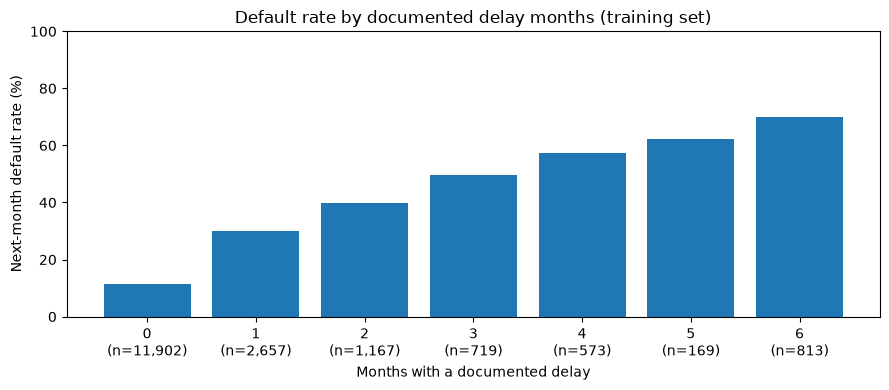

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(summary.index, summary["default_rate_pct"])
ax.set_xticks(summary.index)
ax.set_xticklabels([
    f"{months}\n(n={count:,})"
    for months, count in summary["client_count"].items()
])
ax.set_xlabel("Months with a documented delay")
ax.set_ylabel("Next-month default rate (%)")
ax.set_title("Default rate by documented delay months (training set)")
ax.set_ylim(0, 100)

fig.tight_layout()
plt.show()

In [17]:
from scipy.stats import binomtest

intervals = []
for group in summary.itertuples():
    result = binomtest(k=int(group.default_count), n=int(group.client_count))
    intervals.append(result.proportion_ci(confidence_level=0.95, method="wilson"))

summary_with_ci = summary.assign(
    ci_lower_pct=[100 * interval.low for interval in intervals],
    ci_upper_pct=[100 * interval.high for interval in intervals],
)

summary_with_ci.round(2)

,client_count,default_count,default_rate_pct,ci_lower_pct,ci_upper_pct
documented_delay_months,,,,,
0,11902,1361,11.44,10.88,12.02
1,2657,795,29.92,28.21,31.69
2,1167,466,39.93,37.16,42.77
3,719,358,49.79,46.15,53.44
4,573,329,57.42,53.33,61.40
5,169,105,62.13,54.62,69.10
6,813,568,69.86,66.62,72.92


In [18]:
september_amounts = training[["bill_amt1", "pay_amt1"]].rename(columns={
    "bill_amt1": "September bill",
    "pay_amt1": "September payment",
})

amount_summary = september_amounts.describe(percentiles=[0.50, 0.95]).T
amount_summary[["min", "mean", "50%", "95%", "max"]].rename(columns={
    "50%": "median",
    "95%": "95th percentile",
}).round(2)

,min,mean,median,95th percentile,max
September bill,-165580.0,51473.41,22344.5,201935.90,964511.0
September payment,0.0,5685.20,2138.5,18095.25,873552.0


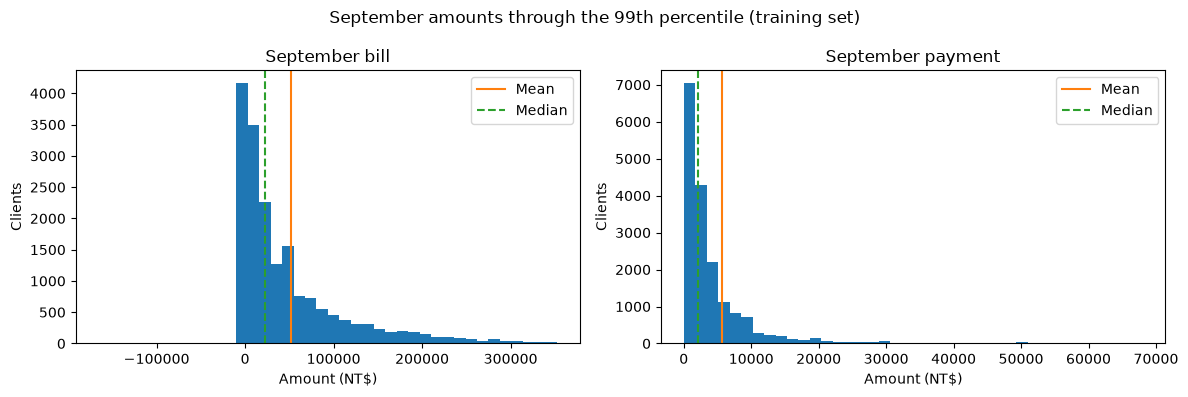

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (label, amounts) in zip(axes, september_amounts.items()):
    cutoff = amounts.quantile(0.99)
    ax.hist(amounts[amounts <= cutoff], bins=40)
    ax.axvline(amounts.mean(), color="tab:orange", label="Mean")
    ax.axvline(amounts.median(), color="tab:green", linestyle="--", label="Median")
    ax.set_title(label)
    ax.set_xlabel("Amount (NT$)")
    ax.set_ylabel("Clients")
    ax.legend()

fig.suptitle("September amounts through the 99th percentile (training set)")
fig.tight_layout()
plt.show()

In [20]:
repayment_features = ["pay_0", "pay_2", "pay_3", "pay_4", "pay_5", "pay_6"]
amount_features = (
    ["limit_bal"]
    + [f"bill_amt{i}" for i in range(1, 7)]
    + [f"pay_amt{i}" for i in range(1, 7)]
)

model_features = repayment_features + amount_features
X_train = training[model_features]
y_train = training["default_payment_next_month"]

print("Predictor shape:", X_train.shape)
print("Outcome count:", len(y_train))
print("Defaults:", y_train.sum())

Predictor shape: (18000, 19)
Outcome count: 18000
Defaults: 3982
